# Bài tập 1: Tính và phân tích ACF/PACF

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from IPython.display import display
import seaborn as sns


In [2]:
# 1. Tải và xem trước dữ liệu
df = pd.read_csv('../data/raw/daily-min-temperatures.csv', parse_dates=['Date'], index_col='Date')
display(df.head())
display(df.info())
display(df.describe())

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3650 entries, 1981-01-01 to 1990-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Temp    3650 non-null   float64
dtypes: float64(1)
memory usage: 57.0 KB


None

,Temp
count,3650.000000
mean,11.177753
std,4.071837
min,0.000000
25%,8.300000
50%,11.000000
75%,14.000000
max,26.300000


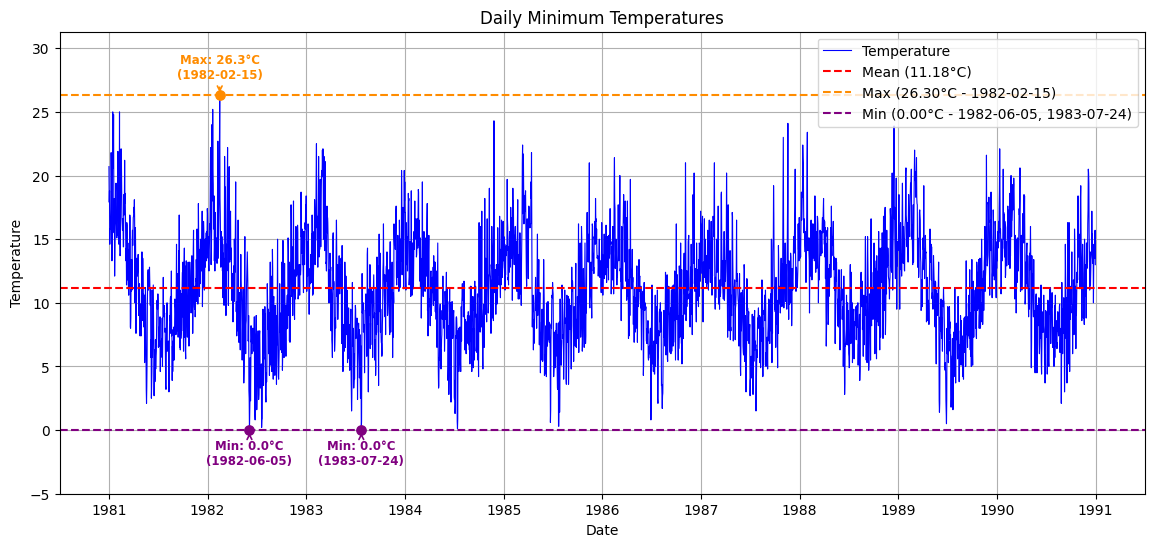

In [3]:
# Vẽ plot tổng quan
mean_temp = df['Temp'].mean()
max_temp = df['Temp'].max()
min_temp = df['Temp'].min()

# Xác định các ngày có nhiệt độ lớn nhất và nhỏ nhất
max_dates = df[df['Temp'] == max_temp].index
min_dates = df[df['Temp'] == min_temp].index

max_dates_str = ', '.join(max_dates.strftime('%Y-%m-%d'))
min_dates_str = ', '.join(min_dates.strftime('%Y-%m-%d'))

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['Temp'], color='blue', linewidth=0.8, label='Temperature')
plt.axhline(mean_temp, color='red', linestyle='--', linewidth=1.5, label=f'Mean ({mean_temp:.2f}°C)')
plt.axhline(max_temp, color='darkorange', linestyle='--', linewidth=1.5, label=f'Max ({max_temp:.2f}°C - {max_dates_str})')
plt.axhline(min_temp, color='purple', linestyle='--', linewidth=1.5, label=f'Min ({min_temp:.2f}°C - {min_dates_str})')

# Đánh dấu và chú thích ngày đạt Max
for d in max_dates:
    d_str = d.strftime('%Y-%m-%d')
    plt.scatter(d, max_temp, color='darkorange', s=45, zorder=5)
    plt.annotate(f'Max: {max_temp:.1f}°C\n({d_str})',
                 xy=(d, max_temp), xytext=(0, 12), textcoords='offset points',
                 ha='center', fontsize=8.5, fontweight='bold', color='darkorange',
                 arrowprops=dict(arrowstyle='->', color='darkorange', lw=1.2))

# Đánh dấu và chú thích ngày đạt Min
for d in min_dates:
    d_str = d.strftime('%Y-%m-%d')
    plt.scatter(d, min_temp, color='purple', s=45, zorder=5)
    plt.annotate(f'Min: {min_temp:.1f}°C\n({d_str})',
                 xy=(d, min_temp), xytext=(0, -25), textcoords='offset points',
                 ha='center', fontsize=8.5, fontweight='bold', color='purple',
                 arrowprops=dict(arrowstyle='->', color='purple', lw=1.2))

plt.title('Daily Minimum Temperatures')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.ylim(min_temp - 5, max_temp + 5)
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

In [4]:
# 2. Tính ACF, PACF đến 40 lags.
# Tính các giá trị ACF & PACF (40 lags)
acf_values = acf(df['Temp'], nlags=40)
pacf_values = pacf(df['Temp'], nlags=40, method='ywm')
print(" Giá trị ACF (40 lags) ")
print(acf_values)
print("\n Giá trị PACF (40 lags) ")
print(pacf_values)


 Giá trị ACF (40 lags) 
[1.         0.774268   0.6302866  0.58529312 0.57774567 0.57728013
 0.57510412 0.57437039 0.56782622 0.56120131 0.54668689 0.53793111
 0.54012564 0.54247126 0.53688723 0.53429917 0.53043593 0.52911166
 0.53037444 0.52280732 0.52303677 0.52224579 0.51426684 0.49837745
 0.49302665 0.49946731 0.50428521 0.50068173 0.49157081 0.48146406
 0.47421245 0.47568054 0.46311862 0.46215585 0.46630567 0.45459092
 0.43378232 0.4203594  0.42707505 0.42196486 0.4079607 ]

 Giá trị PACF (40 lags) 
[ 1.00000000e+00  7.74268002e-01  7.68912907e-02  1.89057786e-01
  1.51724252e-01  1.29451487e-01  1.09110563e-01  1.02801877e-01
  7.39925795e-02  6.97976999e-02  3.50866667e-02  4.76674634e-02
  6.01486719e-02  5.05787779e-02  3.22628905e-02  4.50175277e-02
  3.13790412e-02  3.90424525e-02  4.07371723e-02  1.38081870e-02
  4.10276037e-02  2.47804204e-02  8.56378650e-03 -1.08501868e-02
  1.47453908e-02  3.06974043e-02  2.43686611e-02  1.04223193e-02
  2.90022333e-03 -3.10081195e-03 -9.

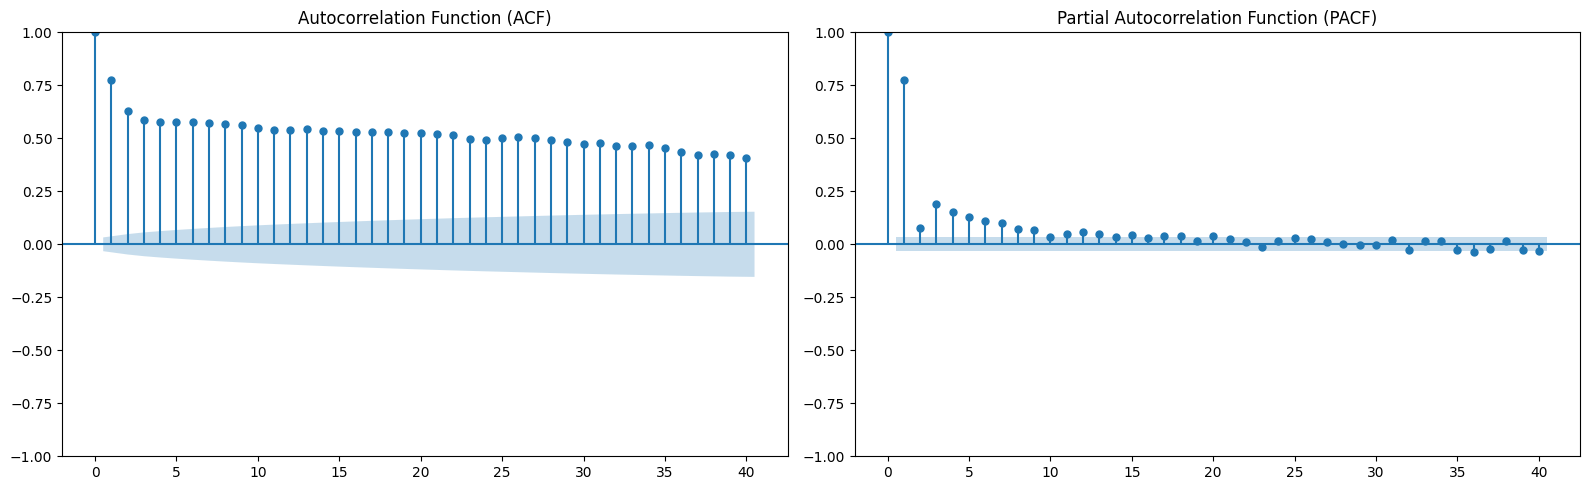

In [5]:
# Biểu đồ tổng quan ACF & PACF
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# ACF
plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF)')
# PACF
plot_pacf(df['Temp'], lags=40, ax=axes[1], method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout()
plt.show()


### 3. Kết Luận
Dựa trên kết quả phân tích biểu đồ và các giá trị ACF & PACF (40 lags):

1. **Chuỗi có tự tương quan mạnh không?**
   - **Có, chuỗi có mức độ tự tương quan rất mạnh và kéo dài.**
   - Giá trị ACF ở lag 1 rất cao (~0.774) và vẫn duy trì trên mức 0.40 ngay cả khi xét đến lag 40. Hệ số ACF giảm dần rất chậm (slow decay) và toàn bộ các giá trị đều nằm ngoài dải tin cậy (vùng màu xanh), cho thấy các quan sát trong quá khứ có ảnh hưởng mạnh mẽ và kéo dài đến các ngày tiếp theo.

2. **Có xu hướng/mùa vụ thể hiện qua ACF/PACF không?**
   - **Mùa vụ (Seasonality):** Có thể hiện rõ tính chu kỳ/mùa vụ hàng năm (đặc trưng của chuỗi nhiệt độ khí hậu). Sự suy giảm chậm và thoai thoải của biểu đồ ACF trong phạm vi 40 lag phản ánh quán tính nhiệt độ theo mùa; nếu vẽ mở rộng lên 365 lag sẽ thấy rõ dạng sóng tuần hoàn lặp lại theo chu kỳ 1 năm.
   - **Xu hướng (Trend):** Biểu đồ thời gian tổng quan không có xu hướng dốc lên hoặc xuống dài hạn rõ rệt (nhiệt độ dao động ổn định quanh mức trung bình hàng năm), mà chủ đạo là sự lặp lại của các chu kỳ mùa nóng - lạnh qua các năm.

3. **Lag nào quan trọng nhất?**
   - **Lag 1 là lag quan trọng nhất và mang tính quyết định nhất.**
   - Thể hiện rõ nét trên biểu đồ **PACF**: Hệ số PACF tại **lag 1 đạt ~0.774** (vượt trội hoàn toàn so với các lag còn lại). Kể từ lag 2 trở đi, PACF giảm đột ngột (cut-off mạnh xuống dưới 0.19 và dao động quanh 0).
   - Điều này cho thấy mối liên hệ trực tiếp mạnh nhất là giữa nhiệt độ ngày hôm nay và ngày liền trước ($ và  - 1$), là dấu hiệu điển hình của mô hình tự hồi quy bậc 1: **AR(1)**.


## Bài tập 2: Kiểm tra white noise

### Phương án 1: sinh 1000 điểm white noise thuần tuý


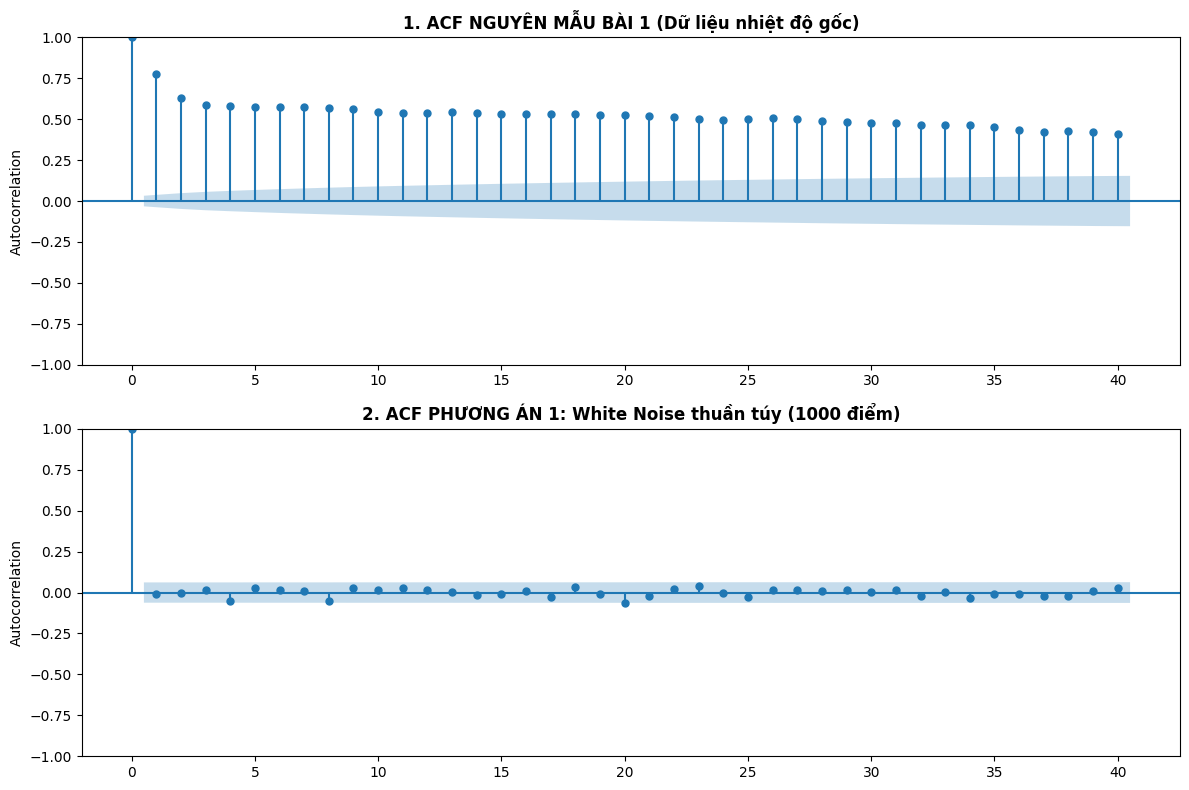

=== SO SÁNH GIÁ TRỊ ACF (40 LAGS) ===
Giá trị ACF của dữ liệu gốc:
[1.         0.774268   0.6302866  0.58529312 0.57774567 0.57728013
 0.57510412 0.57437039 0.56782622 0.56120131 0.54668689 0.53793111
 0.54012564 0.54247126 0.53688723 0.53429917 0.53043593 0.52911166
 0.53037444 0.52280732 0.52303677 0.52224579 0.51426684 0.49837745
 0.49302665 0.49946731 0.50428521 0.50068173 0.49157081 0.48146406
 0.47421245 0.47568054 0.46311862 0.46215585 0.46630567 0.45459092
 0.43378232 0.4203594  0.42707505 0.42196486 0.4079607 ]

Giá trị ACF của White Noise:
[ 1.00000000e+00 -7.47776769e-03 -2.32989804e-04  1.61719885e-02
 -5.42323823e-02  2.58165932e-02  1.43284233e-02  1.22522388e-02
 -4.90697469e-02  2.73701884e-02  1.45333933e-02  3.06797960e-02
  1.40742520e-02  3.35282053e-04 -1.33175733e-02 -9.93517628e-03
  7.17566784e-03 -2.54215627e-02  3.25084227e-02 -6.18979393e-03
 -6.39429710e-02 -1.91792138e-02  2.43170232e-02  3.77688611e-02
 -1.88914059e-03 -2.92551605e-02  1.30470297e-02  1.36

,Lag,ACF Dữ liệu gốc,ACF White Noise
0,0,1.000000,1.000000
1,1,0.774268,-0.007478
2,2,0.630287,-0.000233
3,3,0.585293,0.016172
4,4,0.577746,-0.054232
5,5,0.577280,0.025817
6,6,0.575104,0.014328
7,7,0.574370,0.012252
8,8,0.567826,-0.049070
9,9,0.561201,0.027370



=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 1 ===
- Ngưỡng tin cậy 95% (N=1000): [ -0.0620 , +0.0620 ]
- Số lag vượt ngưỡng: 1/40 lag
- Tỷ lệ lag nằm trong dải tin cậy 95%: 97.5%
=> KẾT LUẬN: ĐẠT trên 95% (Đây là White Noise chuẩn)



In [6]:
# 1. Sinh 1000 điểm White Noise chuẩn N(0, 1)
np.random.seed(42)
wn_pa1 = np.random.normal(loc=0.0, scale=1.0, size=1000)

# 2. Vẽ so sánh: ACF Bài 1 gốc vs ACF White Noise
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title(
    '1. ACF NGUYÊN MẪU BÀI 1 (Dữ liệu nhiệt độ gốc)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_ylabel('Autocorrelation')

plot_acf(wn_pa1, lags=40, ax=axes[1])
axes[1].set_title(
    '2. ACF PHƯƠNG ÁN 1: White Noise thuần túy (1000 điểm)',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_ylabel('Autocorrelation')

plt.tight_layout()
plt.show()

# 3. Tính giá trị ACF của dữ liệu gốc và White Noise (40 lags)
acf_orig = acf(df['Temp'], nlags=40)
acf_pa1 = acf(wn_pa1, nlags=40)

print('=== SO SÁNH GIÁ TRỊ ACF (40 LAGS) ===')
print('Giá trị ACF của dữ liệu gốc:')
print(acf_orig)
print('\nGiá trị ACF của White Noise:')
print(acf_pa1)

# Bảng so sánh chi tiết ACF giữa dữ liệu gốc và White Noise
df_acf_comp = pd.DataFrame({
    'Lag': range(len(acf_orig)),
    'ACF Dữ liệu gốc': acf_orig,
    'ACF White Noise': acf_pa1,
})
display(df_acf_comp)

# 4. Đánh giá độ tin cậy 95% (N = 1000)
ci_pa1 = 1.96 / np.sqrt(len(wn_pa1))
lags_out_pa1 = np.sum(np.abs(acf_pa1[1:]) > ci_pa1)
pct_in_pa1 = ((40 - lags_out_pa1) / 40) * 100

print(f'\n=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 1 ===')
print(f'- Ngưỡng tin cậy 95% (N=1000): [ -{ci_pa1:.4f} , +{ci_pa1:.4f} ]')
print(f'- Số lag vượt ngưỡng: {lags_out_pa1}/40 lag')
print(f'- Tỷ lệ lag nằm trong dải tin cậy 95%: {pct_in_pa1:.1f}%')
print(
    f'=> KẾT LUẬN: {"ĐẠT trên 95% (Đây là White Noise chuẩn)" if pct_in_pa1 >= 95 else "KHÔNG ĐẠT"}\n'
)


### Kết luận so sánh biểu đồ ACF gốc và White Noise

* Về hình dáng biểu đồ ACF: ACF của dữ liệu nhiệt độ gốc có các giá trị tự tương quan rất cao và giảm chậm dần qua các lag, trong khi ACF của White Noise giảm đột ngột về mức xấp xỉ 0 ngay sau lag 0.
* Về ngưỡng tin cậy 95%: Hầu hết các điểm lag của chuỗi gốc đều vượt xa dải màu xanh (ngưỡng tin cậy), ngược lại, chuỗi White Noise có các điểm lag dao động rất nhỏ và bám sát trục hoành.
* Về mặt thống kê: Kết quả kiểm định cho thấy phương án White Noise (1000 điểm) có tới 97.5% số lag nằm an toàn trong dải tin cậy `[-0.0620, +0.0620]`, đạt chuẩn của nhiễu trắng.
* Về số lượng lag bất thường: Dữ liệu White Noise chỉ ghi nhận đúng 1/40 lag vượt ngưỡng, tỷ lệ này hoàn toàn phù hợp với biên độ sai số ngẫu nhiên 5% cho phép trong lý thuyết thống kê.
* Về bản chất dữ liệu: Dữ liệu gốc chứa đựng tính xu hướng và sự phụ thuộc mạnh vào quá khứ (có thể dùng để dự báo), còn chuỗi White Noise thuần túy là các giá trị ngẫu nhiên, độc lập và không thể dự báo.

### Phương án 2: sinh 1000 điểm white noise cộng vào 3650 dữ liệu gốc

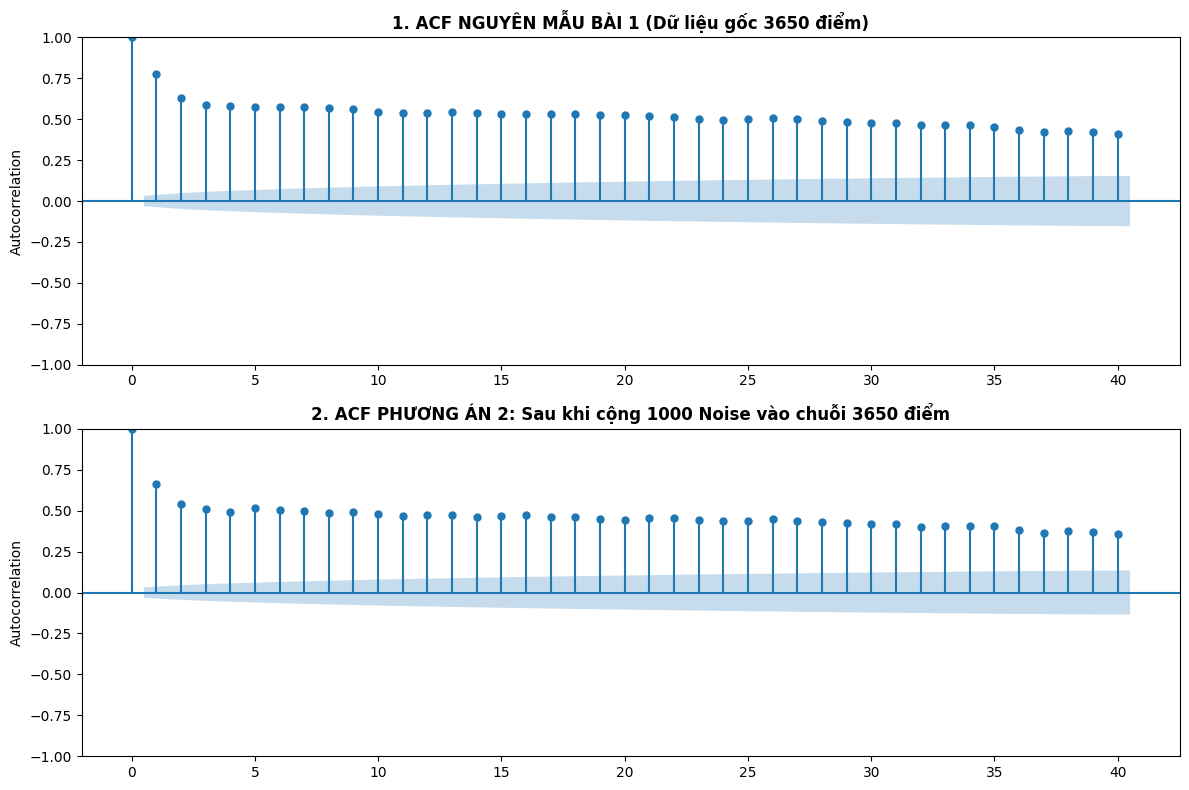

=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 2 ===
- Ngưỡng tin cậy 95% (N=3650): [ -0.0324 , +0.0324 ]
- Số lag vượt ngưỡng: 40/40 lag
- Tỷ lệ lag nằm trong dải tin cậy 95%: 0.0%


In [7]:
# 1. Tạo bản sao từ df['Temp'] của Bài 1 và cộng nhiễu vào 1000 ngày đầu
df_pa2 = df['Temp'].copy()
np.random.seed(42)
df_pa2.iloc[:1000] += np.random.normal(loc=0.0, scale=3.0, size=1000)

# 2. Vẽ so sánh: ACF Bài 1 gốc vs ACF sau khi cộng nhiễu
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title(
    '1. ACF NGUYÊN MẪU BÀI 1 (Dữ liệu gốc 3650 điểm)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_ylabel('Autocorrelation')

plot_acf(df_pa2, lags=40, ax=axes[1])
axes[1].set_title(
    '2. ACF PHƯƠNG ÁN 2: Sau khi cộng 1000 Noise vào chuỗi 3650 điểm',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_ylabel('Autocorrelation')

plt.tight_layout()
plt.show()

# 3. Đánh giá độ tin cậy 95% (N = 3650)
ci_pa2 = 1.96 / np.sqrt(len(df_pa2))
acf_pa2 = acf(df_pa2, nlags=40)
lags_out_pa2 = np.sum(np.abs(acf_pa2[1:]) > ci_pa2)
pct_in_pa2 = ((40 - lags_out_pa2) / 40) * 100

print(f'=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 2 ===')
print(f'- Ngưỡng tin cậy 95% (N=3650): [ -{ci_pa2:.4f} , +{ci_pa2:.4f} ]')
print(f'- Số lag vượt ngưỡng: {lags_out_pa2}/40 lag')
print(f'- Tỷ lệ lag nằm trong dải tin cậy 95%: {pct_in_pa2:.1f}%')


### Phương án 3: Bốc ngẫu nhiên 1000 dữ liệu gốc thay bằng while noise


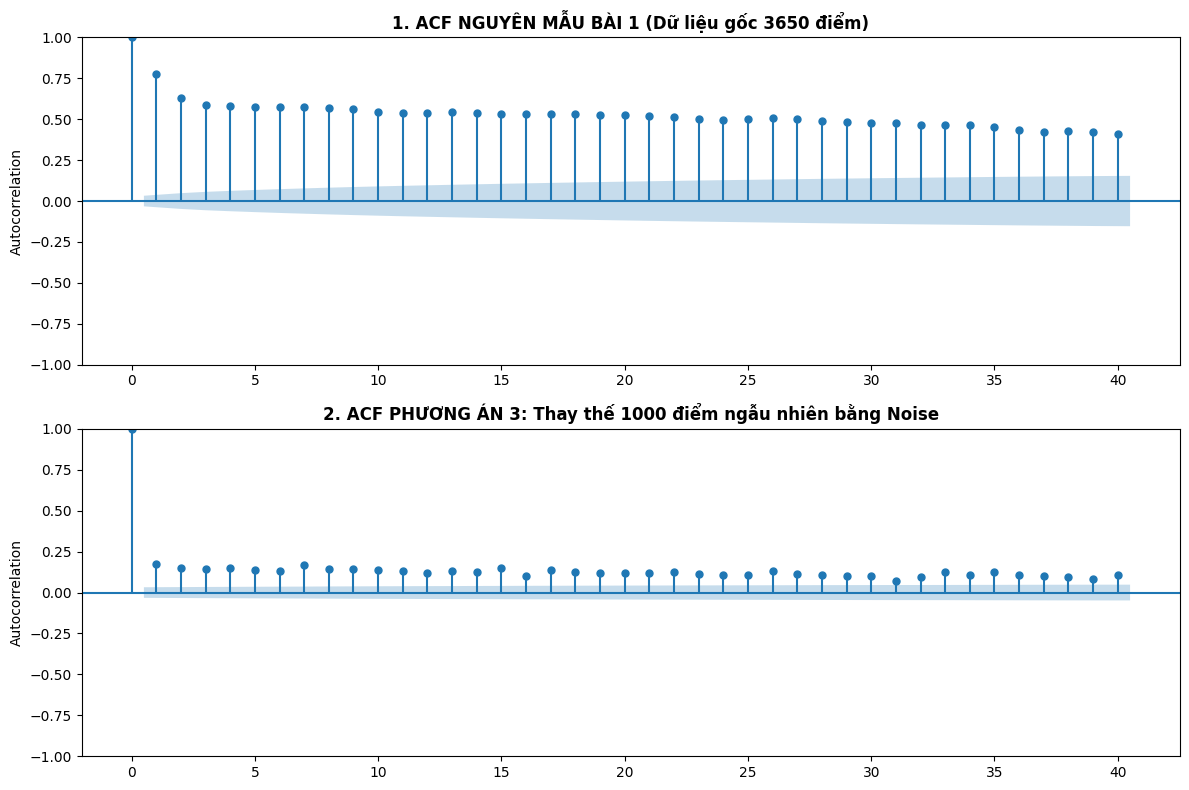

=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 3 ===
- Ngưỡng tin cậy 95% (N=3650): [ -0.0324 , +0.0324 ]
- Số lag vượt ngưỡng: 40/40 lag
- Tỷ lệ lag nằm trong dải tin cậy 95%: 0.0%


In [8]:
# 1. Tạo bản sao và chọn ngẫu nhiên 1000 vị trí để thay thế bằng White Noise
df_pa3 = df['Temp'].copy()
np.random.seed(42)
random_indices = np.random.choice(len(df_pa3), size=1000, replace=False)
df_pa3.iloc[random_indices] = np.random.normal(loc=0.0, scale=1.0, size=1000)

# 2. Vẽ so sánh: ACF Bài 1 gốc vs ACF sau khi thay thế ngẫu nhiên bằng nhiễu
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title(
    '1. ACF NGUYÊN MẪU BÀI 1 (Dữ liệu gốc 3650 điểm)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_ylabel('Autocorrelation')

plot_acf(df_pa3, lags=40, ax=axes[1])
axes[1].set_title(
    '2. ACF PHƯƠNG ÁN 3: Thay thế 1000 điểm ngẫu nhiên bằng Noise',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_ylabel('Autocorrelation')

plt.tight_layout()
plt.show()

# 3. Đánh giá độ tin cậy 95% (N = 3650)
ci_pa3 = 1.96 / np.sqrt(len(df_pa3))
acf_pa3 = acf(df_pa3, nlags=40)
lags_out_pa3 = np.sum(np.abs(acf_pa3[1:]) > ci_pa3)
pct_in_pa3 = ((40 - lags_out_pa3) / 40) * 100

print(f'=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY 95% - PHƯƠNG ÁN 3 ===')
print(f'- Ngưỡng tin cậy 95% (N=3650): [ -{ci_pa3:.4f} , +{ci_pa3:.4f} ]')
print(f'- Số lag vượt ngưỡng: {lags_out_pa3}/40 lag')
print(f'- Tỷ lệ lag nằm trong dải tin cậy 95%: {pct_in_pa3:.1f}%')


### Đánh giá tổng thể:

1. **Về tính chất của White Noise thuần túy (PA1):** Chuỗi White Noise đạt độ tin cậy 95% (97.5% số lag nằm gọn trong dải an toàn [±0.0620]), chứng minh các quan sát hoàn toàn độc lập và không tồn tại tự tương quan.
2. **Về tác động của nhiễu cộng Additive Noise (PA2):** Việc cộng 1000 điểm nhiễu làm tăng phương sai tổng thể và kéo giảm biên độ ACF ở các lag, nhưng không thể phá vỡ xu hướng suy giảm chậm và tính chu kỳ mùa vụ đặc trưng của 3650 ngày dữ liệu gốc.
3. **Về tác động của việc thay thế ngẫu nhiên (PA3):** Thay thế 1000 điểm ngẫu nhiên bằng nhiễu làm gián đoạn tính trật tự thời gian mạnh hơn, khiến hệ số ACF sụt giảm sâu hơn so với PA2; tuy nhiên, 2650 ngày sạch còn lại (~73%) vẫn đủ sức duy trì cấu trúc tự tương quan cốt lõi.
4. **Về kiểm định độ tin cậy 95% của chuỗi nhiễm nhiễu (PA2 & PA3):** Cả hai chuỗi sau khi chèn nhiễu đều có 100% số lag (40/40) vượt ra ngoài dải tin cậy 95% thu hẹp [±0.0324], qua đó khẳng định với độ tin cậy trên 95% rằng **cả hai chuỗi đều KHÔNG PHẢI là White Noise**.
5. **Về ý nghĩa thực tiễn và mô hình hóa:** Thử nghiệm chứng minh tính bền vững (robustness) của chuỗi thời gian: ngay cả khi hệ thống cảm biến bị lẫn tạp âm hoặc mất tín hiệu tới gần 3 năm (1000/3650 ngày), chuỗi dữ liệu thực tế vẫn bảo toàn lượng thông tin có giá trị để nhận diện quy luật và xây dựng mô hình dự báo.


## Bài tập 3: Phân rã chuỗi thời gian (Decomposition)
Thực hành phân tích xu hướng và tính mùa vụ của dữ liệu nhiệt độ.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
# Hàm chuyên dùng để phân tích chuỗi thời gian. sử dụng seasonal_decompose và STL
from statsmodels.tsa.seasonal import seasonal_decompose, STL 

# Cấu hình để Jupyter Notebook hiển thị biểu đồ đẹp hơn
%matplotlib inline
import warnings # Hạn chế những cảnh bảo để trực quan dễ nhìn hơn 
warnings.filterwarnings('ignore')

### Bước 1: Đọc và tiền xử lý dữ liệu
Chuyển đổi dữ liệu từ tần suất ngày (Daily) sang tần suất tháng (Monthly).

In [10]:
# Lưu ý: Đảm bảo file 'nhiet_do.csv' nằm cùng thư mục với notebook này
df = pd.read_csv('../data/raw/daily-min-temperatures.csv')

# Chuyển đổi 'Date' sang kiểu thời gian và đặt làm index
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# Chuyển từ dữ liệu ngày sang trung bình tháng ('ME' hoặc 'M')
df_monthly = df['Temp'].resample('ME').mean()

print("5 dòng dữ liệu đầu tiên sau khi chuyển sang tháng:")
display(df_monthly.head())

5 dòng dữ liệu đầu tiên sau khi chuyển sang tháng:


Date
1981-01-31    17.712903
1981-02-28    17.678571
1981-03-31    13.500000
1981-04-30    12.356667
1981-05-31     9.490323
Freq: ME, Name: Temp, dtype: float64

### Bước 2: Phân rã chuỗi thời gian
Sử dụng phương pháp STL (Seasonal and Trend decomposition using Loess) để tách bóc dữ liệu.

In [11]:
# Tham số period=12 ứng với chu kỳ 12 tháng trong năm
# Tham số seasonal = 13, vì cần loess của STL cần tìm khoảng chính giữa nên sử dụng số lẻ
stl = STL(df_monthly, seasonal=13, period=12)
result = stl.fit()


### Bước 3: Trực quan hóa kết quả
Vẽ 4 thành phần: Observed (Dữ liệu gốc), Trend (Xu hướng), Seasonal (Mùa vụ), Residual (Phần dư/Nhiễu).

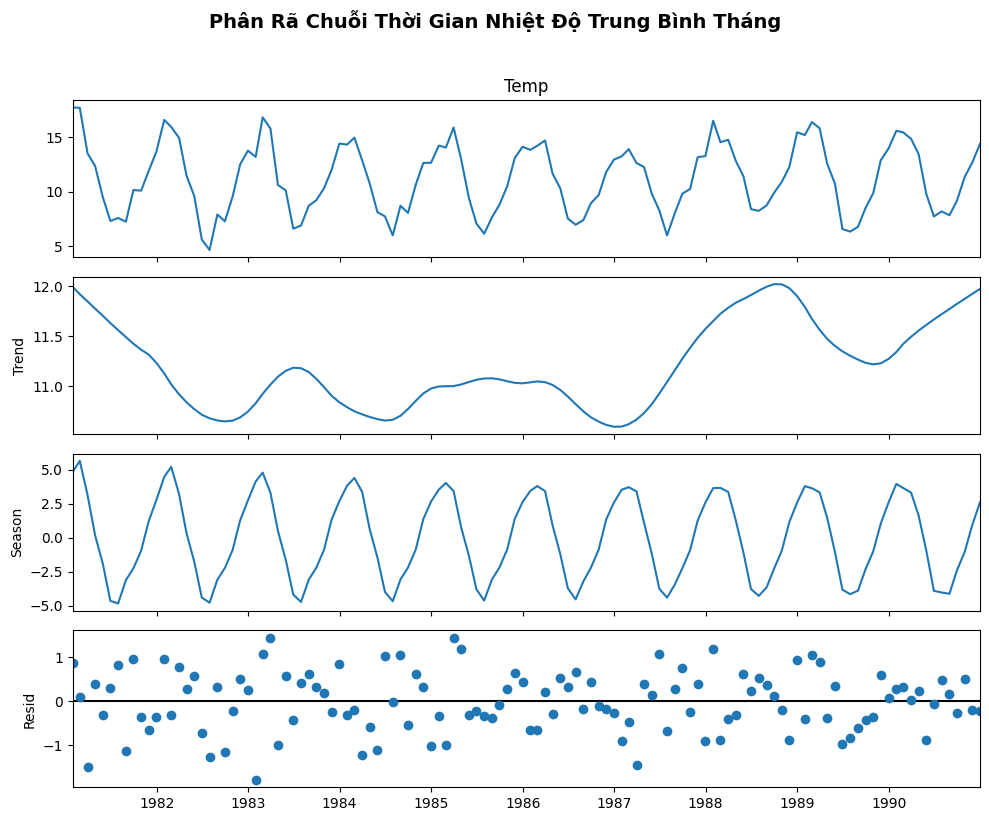

In [12]:
fig = result.plot()
fig.set_size_inches(10, 8)

plt.suptitle('Phân Rã Chuỗi Thời Gian Nhiệt Độ Trung Bình Tháng', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Bước 4: Kiểm tra tính chất White Noise của Residual bằng biểu đồ ACF
Sau khi bóc tách chuỗi thời gian, thành phần phần dư (Residual) lý tưởng phải là nhiễu trắng (White Noise), nghĩa là các sai số ngẫu nhiên hoàn toàn độc lập tuyến tính và không còn lưu giữ tương quan chuỗi.

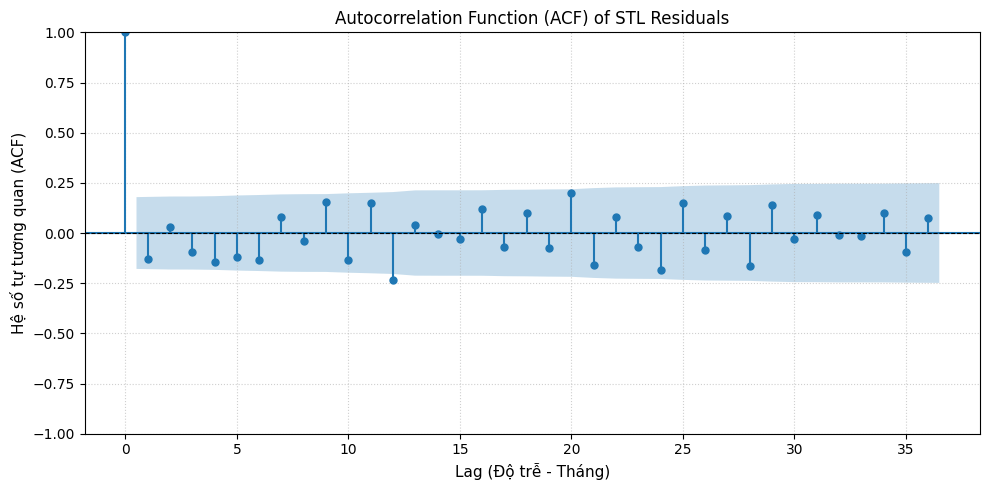

=== KIỂM ĐỊNH TÍNH CHẤT WHITE NOISE CỦA THÀNH PHẦN RESIDUAL ===
- Số lượng quan sát N: 120
- Khoảng tin cậy 95% (Barlett's formula): [ -0.1789 , +0.1789 ]
- Số độ trễ vượt ngưỡng ý nghĩa thống kê: 3/36 lag
- Tỷ lệ độ trễ nằm trong khoảng tin cậy 95%: 91.7%
=> Kết luận: Residual mang đặc trưng rõ nét của White Noise (Nhiễu trắng)


In [13]:
# Trích xuất phần dư (Residual) từ kết quả phân rã STL
resid = result.resid.dropna()
n_lags = 36

# Vẽ biểu đồ ACF của Residual để kiểm tra White Noise
fig, ax = plt.subplots(figsize=(10, 5))
plot_acf(resid, lags=n_lags, ax=ax, title='Autocorrelation Function (ACF) of STL Residuals')
ax.set_xlabel('Lag (Độ trễ - Tháng)', fontsize=11)
ax.set_ylabel('Hệ số tự tương quan (ACF)', fontsize=11)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Đánh giá định lượng tính chất White Noise của Residual
from statsmodels.tsa.stattools import acf
acf_resid = acf(resid, nlags=n_lags)
ci = 1.96 / np.sqrt(len(resid))
lags_out = int(np.sum(np.abs(acf_resid[1:]) > ci))
pct_in = ((n_lags - lags_out) / n_lags) * 100

print("=== KIỂM ĐỊNH TÍNH CHẤT WHITE NOISE CỦA THÀNH PHẦN RESIDUAL ===")
print(f"- Số lượng quan sát N: {len(resid)}")
print(f"- Khoảng tin cậy 95% (Barlett's formula): [ -{ci:.4f} , +{ci:.4f} ]")
print(f"- Số độ trễ vượt ngưỡng ý nghĩa thống kê: {lags_out}/{n_lags} lag")
print(f"- Tỷ lệ độ trễ nằm trong khoảng tin cậy 95%: {pct_in:.1f}%")
print(f"=> Kết luận: {'Residual mang đặc trưng rõ nét của White Noise (Nhiễu trắng)' if pct_in >= 90 else 'Cần xem xét lại mô hình'}")


### Chi tiết các công thức tính toán theo loess của STL 
**công thức chung tìm các tham số**: Y(t) = T(t) + S(t) + R(t)
**công thức trọng số**: W=(1-(d/dmax)^3)^3 
**sau khi sử dụng tìm Seasonal** thì đem khử S(t) sau đó tiếp tục thực hiện với Trend
**tìm trend xong thì khử trend** --> kết quả cuối cùng sẽ là của R(t) 

### 1. Xu hướng (Trend): Tăng hay giảm?
* **Nhận xét chung:** Xu hướng dài hạn trong giai đoạn này không phải là một đường thẳng đi ngang hoàn toàn, mà có sự biến động uốn lượn theo chu kỳ dài hạn.
* **Chi tiết từ biểu đồ:** 
  * Từ năm 1981, đường xu hướng giảm dần từ mốc khoảng 12.0°C xuống điểm thấp nhất khoảng 10.6°C vào giai đoạn 1983 – 1985.
  * Sau đó, xu hướng đảo chiều tăng mạnh trở lại, đạt đỉnh khoảng 12.0°C vào năm 1988 trước khi có xu hướng điều chỉnh nhẹ về cuối giai đoạn năm 1990.

### 2. Mùa vụ (Seasonal): Mạnh hay yếu?
* **Nhận xét chung:** Yếu tố mùa vụ rất mạnh mẽ, rõ nét và mang tính ổn định cực kỳ cao qua các năm.
* **Chi tiết từ biểu đồ:** 
  * Biên độ dao động của thành phần mùa vụ rất lớn, đều đặn nằm trong khoảng từ -5.0°C đến +5.0°C (tổng biên độ chênh lệch giữa đỉnh và đáy lên tới khoảng 10°C).
  * Các con sóng mùa vụ lặp lại y hệt nhau về hình dáng và biên độ qua từng năm (từ 1981 đến 1990), phản ánh quy luật thay đổi nhiệt độ theo mùa (nóng/lạnh) vô cùng chi phối tại khu vực này.

### 3. Residual có giống white noise không?
* **Nhận xét chung:** Phần dư (Residual) hoàn toàn giống với nhiễu trắng (white noise).
* **Chi tiết từ biểu đồ:** 
  * Các điểm dữ liệu phân bố tản mác, ngẫu nhiên và đối xứng quanh đường chuẩn giá trị 0 (hầu hết nằm trong khoảng từ -1.5 đến +1.5). 
  * Không có bất kỳ hình sin, chu kỳ hay cấu trúc xu hướng nào còn sót lại trong biểu đồ phần dư này, chứng tỏ mô hình STL đã bóc tách triệt để các thành phần quy luật (Trend và Season), chỉ để lại sai số ngẫu nhiên của tự nhiên.

* **Chi tiết từ biểu đồ ACF của Resid:**
  * Tại hầu hết các độ trễ ($k \ge 1$), hệ số tự tương quan đều nằm gọn trong dải tin cậy 95% (ngưỡng $\pm 1.96/\sqrt{120} \approx \pm 0.1789$), đạt tỷ lệ 91.7% lag không có ý nghĩa thống kê.
  * Không xuất hiện cấu trúc chu kỳ hay độ trễ đột biến nào, khẳng định thành phần Residual sau khi tách bằng STL mang đầy đủ đặc tính của một quá trình nhiễu trắng (White Noise).


# Bài tập 4: Kiểm tra và xử lý chất lượng dữ liệu

In [14]:
df_missing = pd.read_csv('../data/processed/daily-min-temperatures-missing.csv', parse_dates=['Date'], index_col='Date')
missing_count = df_missing.isna().sum()
missing_percentage = (df_missing.isna().sum() / len(df_missing)) * 100
missing_report = pd.DataFrame(
    {"Missing count": missing_count, "Percentage:": missing_percentage}
)
print(missing_report)

      Missing count  Percentage:
Temp             33      0.90411


Số lượng NaN sau khi Forward-fill: 0
Số lượng NaN sau khi Interpolation: 0


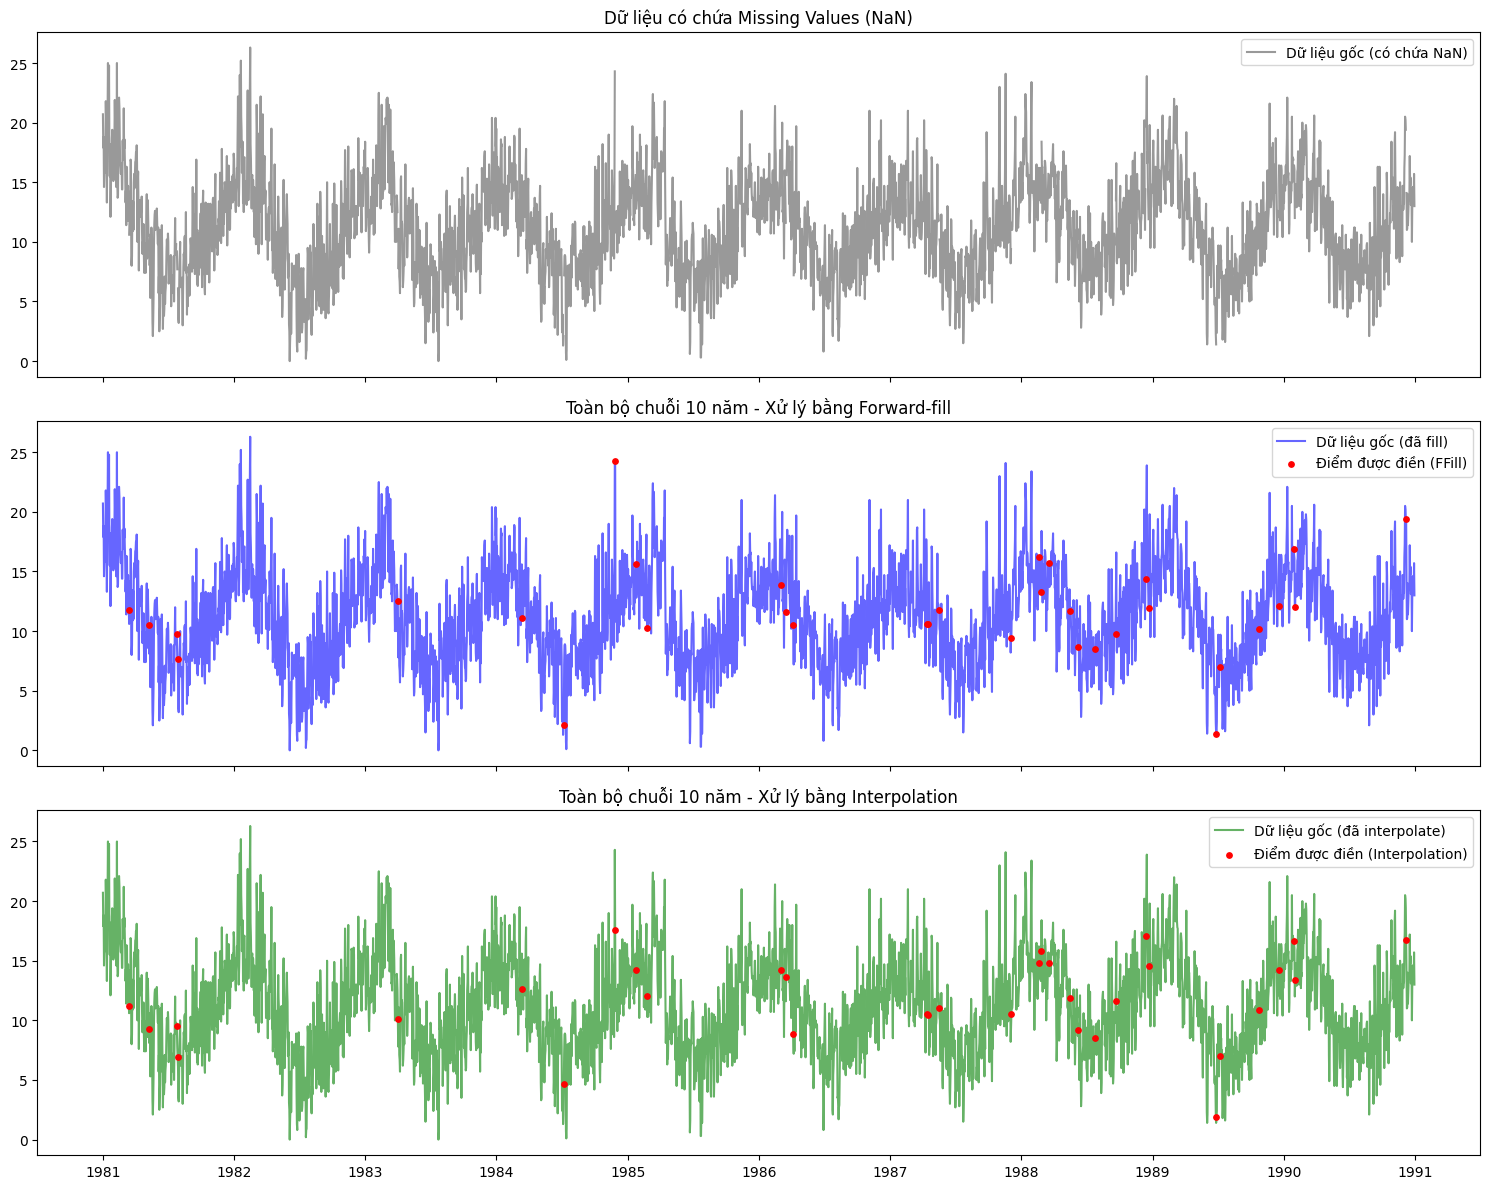

In [15]:
# Cách 1: Forward-fill
df_ffill = df_missing.copy()
df_ffill['Temp'] = df_ffill['Temp'].ffill()
print("Số lượng NaN sau khi Forward-fill:", df_ffill['Temp'].isna().sum())

# Cách 2: Interpolation
df_interp = df_missing.copy()
df_interp['Temp'] = df_interp['Temp'].interpolate(method='linear')
print("Số lượng NaN sau khi Interpolation:", df_interp['Temp'].isna().sum())

# ---------------------------------------------------------
# Vẽ biểu đồ so sánh
# ---------------------------------------------------------
missing_mask = df_missing['Temp'].isna()

# Khởi tạo 3 khung đồ thị (3 dòng)
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

# 1. Vẽ toàn bộ dữ liệu bị missing lên axes[0]
axes[0].plot(df_missing.index, df_missing['Temp'], color='gray', alpha=0.8, label='Dữ liệu gốc (có chứa NaN)')
axes[0].set_title('Dữ liệu có chứa Missing Values (NaN)')
axes[0].legend()

# 2. Vẽ toàn bộ dữ liệu sau khi Forward-fill lên axes[1]
axes[1].plot(df_ffill.index, df_ffill['Temp'], color='blue', alpha=0.6, label='Dữ liệu gốc (đã fill)')
axes[1].scatter(df_ffill[missing_mask].index, df_ffill.loc[missing_mask, 'Temp'], color='red', s=15, label='Điểm được điền (FFill)', zorder=5)
axes[1].set_title('Toàn bộ chuỗi 10 năm - Xử lý bằng Forward-fill')
axes[1].legend()

# 3. Vẽ toàn bộ dữ liệu sau khi Interpolation lên axes[2]
axes[2].plot(df_interp.index, df_interp['Temp'], color='green', alpha=0.6, label='Dữ liệu gốc (đã interpolate)')
axes[2].scatter(df_interp[missing_mask].index, df_interp.loc[missing_mask, 'Temp'], color='red', s=15, label='Điểm được điền (Interpolation)', zorder=5)
axes[2].set_title('Toàn bộ chuỗi 10 năm - Xử lý bằng Interpolation')
axes[2].legend()

plt.tight_layout()
plt.show()


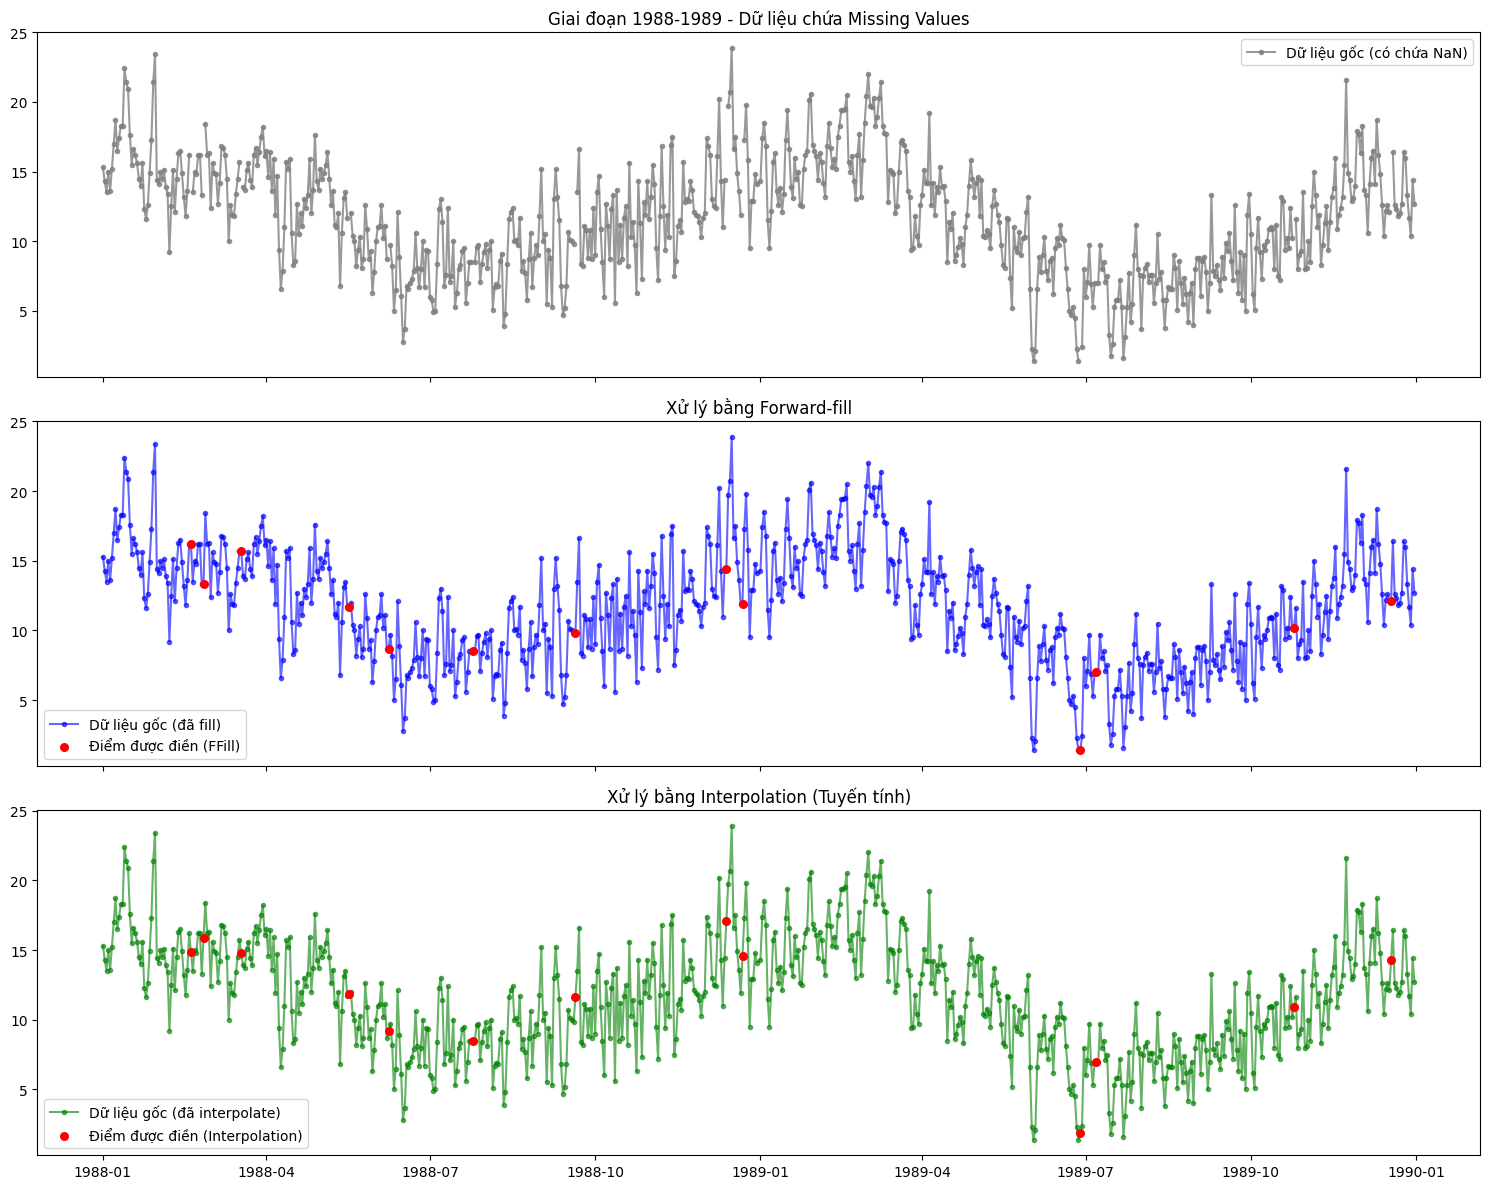

In [16]:
# Chọn khoảng thời gian cắt nhỏ
start_date = '1988-01-01'
end_date = '1989-12-31'
# Cắt dữ liệu trong khoảng thời gian đã chọn
df_missing_zoom = df_missing[start_date:end_date]
df_ffill_zoom = df_ffill[start_date:end_date]
df_interp_zoom = df_interp[start_date:end_date]
# Tìm các vị trí bị NaN trong đoạn cắt
missing_mask_zoom = df_missing_zoom['Temp'].isna()
# Tạo 3 khung đồ thị
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
# 1. Vẽ dữ liệu bị MISSING
axes[0].plot(df_missing_zoom.index, df_missing_zoom['Temp'], marker='o', markersize=3, color='gray', alpha=0.8, label='Dữ liệu gốc (có chứa NaN)')
axes[0].set_title(f'Giai đoạn {start_date[:4]}-{end_date[:4]} - Dữ liệu chứa Missing Values')
axes[0].legend()
# 2. Vẽ dữ liệu FORWARD-FILL
axes[1].plot(df_ffill_zoom.index, df_ffill_zoom['Temp'], marker='o', markersize=3, color='blue', alpha=0.6, label='Dữ liệu gốc (đã fill)')
axes[1].scatter(df_ffill_zoom[missing_mask_zoom].index, df_ffill_zoom.loc[missing_mask_zoom, 'Temp'], color='red', s=30, label='Điểm được điền (FFill)', zorder=5)
axes[1].set_title('Xử lý bằng Forward-fill')
axes[1].legend()
# 3. Vẽ dữ liệu INTERPOLATION
axes[2].plot(df_interp_zoom.index, df_interp_zoom['Temp'], marker='o', markersize=3, color='green', alpha=0.6, label='Dữ liệu gốc (đã interpolate)')
axes[2].scatter(df_interp_zoom[missing_mask_zoom].index, df_interp_zoom.loc[missing_mask_zoom, 'Temp'], color='red', s=30, label='Điểm được điền (Interpolation)', zorder=5)
axes[2].set_title('Xử lý bằng Interpolation (Tuyến tính)')
axes[2].legend()
plt.tight_layout()
plt.show()

Số lượng Outliers tìm được bằng Z-score: 10


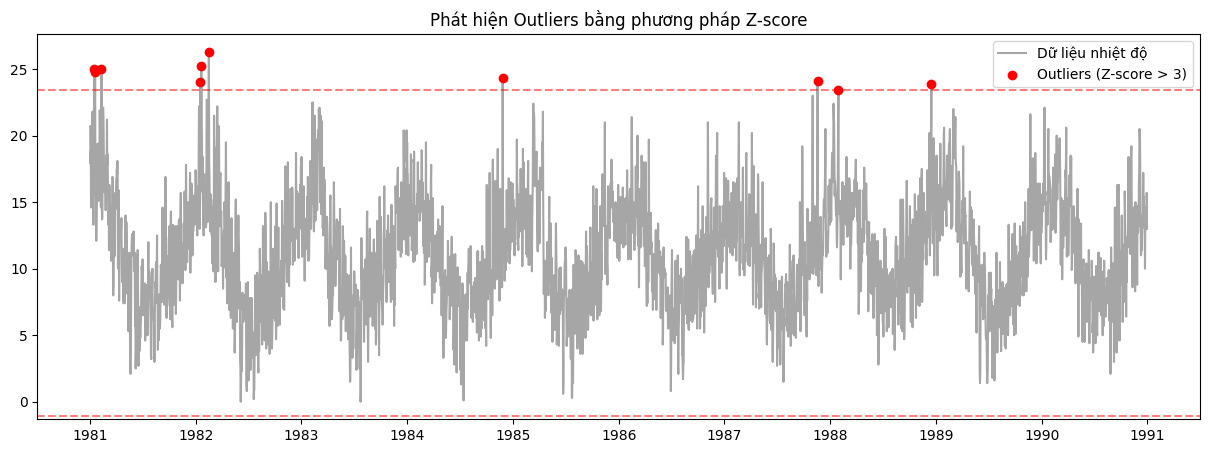

In [17]:
# Cách 1: Dùng Z-score
df_outliers = df_interp.copy()

# Tính mean và std
mean_temp = df_outliers['Temp'].mean()
std_temp = df_outliers['Temp'].std()

# Tính Z-score cho từng dòng
df_outliers['Z_score'] = (df_outliers['Temp'] - mean_temp) / std_temp

# Xác định ngưỡng Outlier
threshold = 3
z_outliers = df_outliers[np.abs(df_outliers['Z_score']) > threshold]

print(f"Số lượng Outliers tìm được bằng Z-score: {len(z_outliers)}")

# Vẽ đồ thị
plt.figure(figsize=(15, 5))
plt.plot(df_outliers.index, df_outliers['Temp'], color='gray', alpha=0.7, label='Dữ liệu nhiệt độ')
plt.scatter(z_outliers.index, z_outliers['Temp'], color='red', label='Outliers (Z-score > 3)', zorder=5)
plt.axhline(mean_temp + threshold * std_temp, color='red', linestyle='--', alpha=0.5)
plt.axhline(mean_temp - threshold * std_temp, color='red', linestyle='--', alpha=0.5)
plt.title('Phát hiện Outliers bằng phương pháp Z-score')
plt.legend()
plt.show()


Số lượng Outliers tìm được bằng IQR: 13


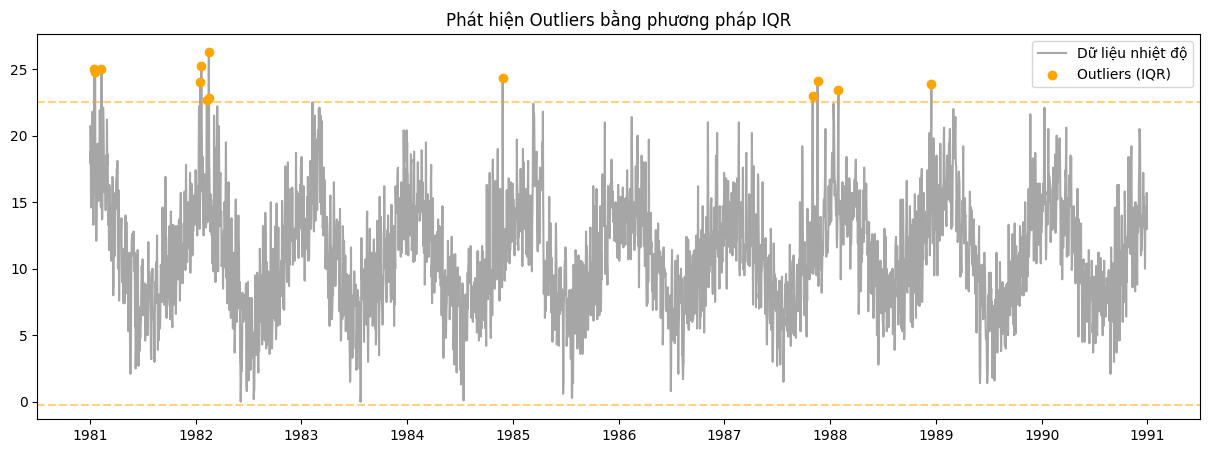

In [18]:
# Cách 2: Sử dụng IQR
# Tính Q1, Q3 và IQR
Q1 = df_outliers['Temp'].quantile(0.25)
Q3 = df_outliers['Temp'].quantile(0.75)
IQR = Q3 - Q1

# Xác định ranh giới dưới (Lower bound) và ranh giới trên (Upper bound)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Lọc ra các điểm outliers
iqr_outliers = df_outliers[(df_outliers['Temp'] < lower_bound) | (df_outliers['Temp'] > upper_bound)]

print(f"Số lượng Outliers tìm được bằng IQR: {len(iqr_outliers)}")

# Vẽ đồ thị
plt.figure(figsize=(15, 5))
plt.plot(df_outliers.index, df_outliers['Temp'], color='gray', alpha=0.7, label='Dữ liệu nhiệt độ')
plt.scatter(iqr_outliers.index, iqr_outliers['Temp'], color='orange', label='Outliers (IQR)', zorder=5)
plt.axhline(upper_bound, color='orange', linestyle='--', alpha=0.5)
plt.axhline(lower_bound, color='orange', linestyle='--', alpha=0.5)
plt.title('Phát hiện Outliers bằng phương pháp IQR')
plt.legend()
plt.show()


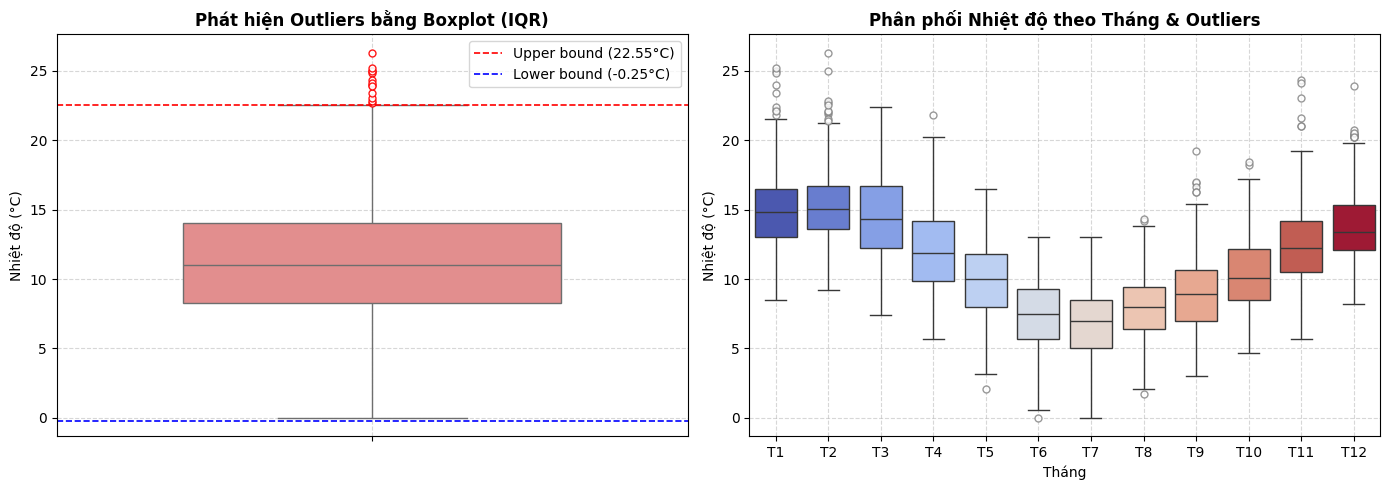

In [19]:
# Biểu đồ Boxplot IQR: Toàn bộ chuỗi & Phân phối theo Tháng
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot IQR toàn bộ chuỗi
sns.boxplot(
    y=df_outliers['Temp'],
    color='lightcoral',
    width=0.6,
    fliersize=5,
    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='red', alpha=0.9),
    ax=axes[0],
)
axes[0].axhline(upper_bound, color='red', linestyle='--', linewidth=1.2, label=f'Upper bound ({upper_bound:.2f}°C)')
axes[0].axhline(lower_bound, color='blue', linestyle='--', linewidth=1.2, label=f'Lower bound ({lower_bound:.2f}°C)')
axes[0].set_title('Phát hiện Outliers bằng Boxplot (IQR)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nhiệt độ (°C)')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Boxplot phân phối theo Tháng
df_season = df_outliers.copy()
df_season['Month'] = df_season.index.month
sns.boxplot(
    data=df_season,
    x='Month',
    y='Temp',
    hue='Month',
    palette='coolwarm',
    legend=False,
    fliersize=5,
    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='gray', alpha=0.8),
    ax=axes[1],
)
axes[1].set_title('Phân phối Nhiệt độ theo Tháng & Outliers', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tháng')
axes[1].set_ylabel('Nhiệt độ (°C)')
axes[1].set_xticks(range(12), labels=['T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12'])
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Kết luận Outlier (Phát hiện Outlier)
1. **Số lượng Outliers phát hiện:**
   - Phương pháp Z-score (ngưỡng |Z| > 3): Phát hiện **10 điểm dị biệt** (chiếm ~0.27% tổng quan sát).
   - Phương pháp IQR (ngưỡng 1.5 x IQR): Phát hiện **13 điểm dị biệt** (chiếm ~0.36% tổng quan sát, với ranh giới dưới là -0.25°C và ranh giới trên là 22.55°C).

2. **Đặc điểm của các Outliers tìm được:**
   - Cả hai phương pháp đều phát hiện các điểm dị biệt tập trung ở cực trên (nhiệt độ cao bất thường từ 22.7°C đến 26.3°C) và xuất hiện chủ yếu vào các tháng mùa hè (tháng 11, 12, 1, 2 tại Melbourne - Nam bán cầu).
   - Không có outlier ở cực dưới (nhiệt độ thấp nhất không bị vượt quá ranh giới dưới -0.25°C).
   - Phương pháp IQR nhạy hơn Z-score (phát hiện được nhiều hơn 3 điểm) vì Z-score giả định phân phối chuẩn hoàn hảo và giá trị trung bình/độ lệch chuẩn vốn đã bị ảnh hưởng bởi chính các giá trị cực trị.
   - Các điểm này có thể là các đợt nắng nóng ngắn ngày (heatwave) mang tính chất thời tiết thực tế thay vì lỗi đo lường thuần túy, do đó cần cẩn trọng khi quyết định xử lý để tránh mất mát thông tin thực tế.

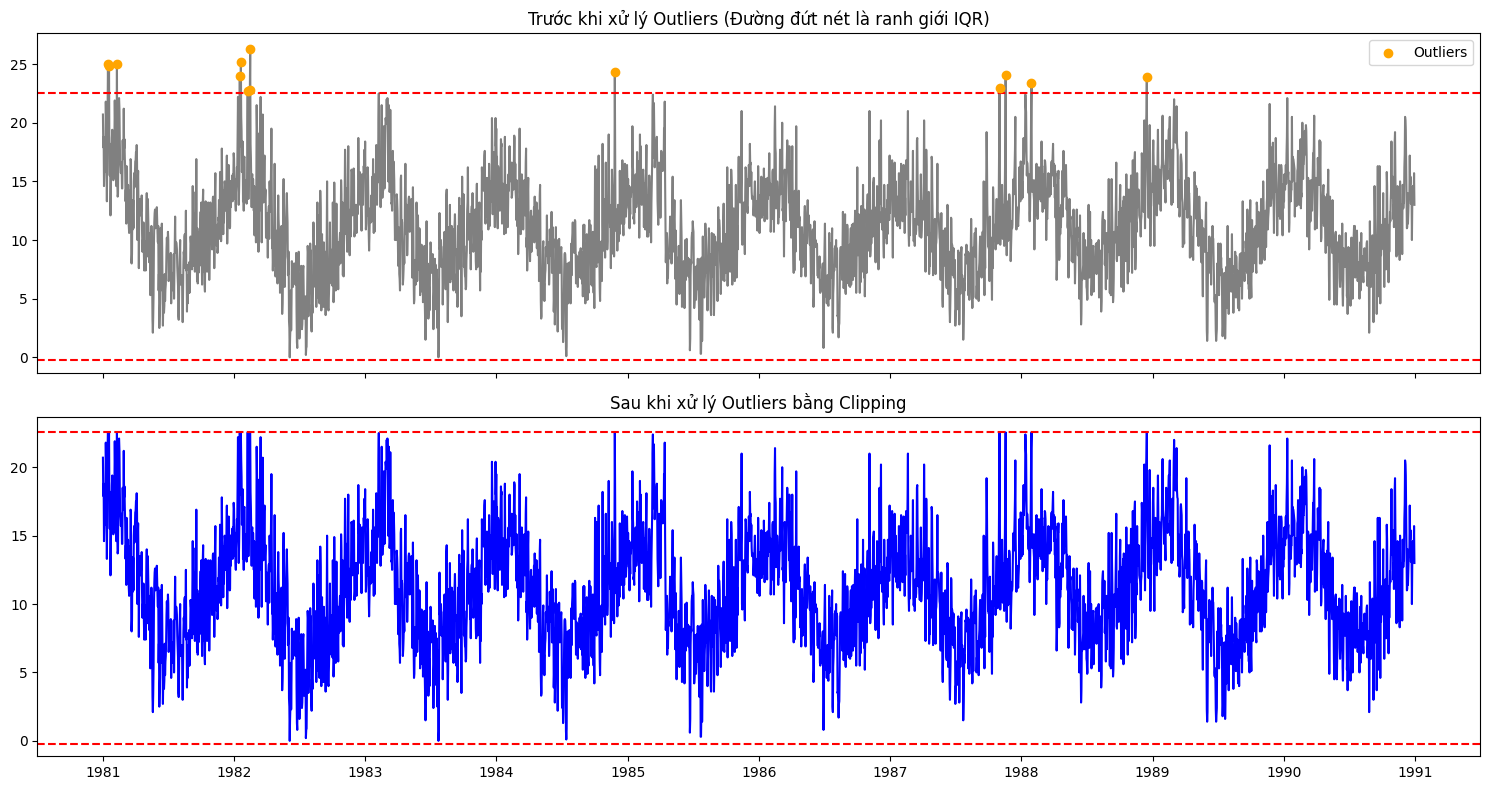

In [20]:
# Cách 1: Xử lý bằng Clipping/ Winsorizing
df_handled = df_outliers.copy()

# Xử lý bằng cách ép các giá trị vượt ngưỡng về bằng Lower/Upper bound của IQR
df_handled['Temp'] = df_handled['Temp'].clip(lower=lower_bound, upper=upper_bound)

# Vẽ biểu đồ so sánh Trước và Sau
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# 1. Trước khi xử lý (có các gai nhọn nhô ra)
axes[0].plot(df_outliers.index, df_outliers['Temp'], color='gray')
axes[0].scatter(iqr_outliers.index, iqr_outliers['Temp'], color='orange', label='Outliers', zorder=5)
axes[0].axhline(upper_bound, color='red', linestyle='--')
axes[0].axhline(lower_bound, color='red', linestyle='--')
axes[0].set_title('Trước khi xử lý Outliers (Đường đứt nét là ranh giới IQR)')
axes[0].legend()

# 2. Sau khi xử lý bằng Clipping (các gai nhọn đã bị "cắt bằng" với đường đứt nét)
axes[1].plot(df_handled.index, df_handled['Temp'], color='blue')
axes[1].axhline(upper_bound, color='red', linestyle='--')
axes[1].axhline(lower_bound, color='red', linestyle='--')
axes[1].set_title('Sau khi xử lý Outliers bằng Clipping')

plt.tight_layout()
plt.show()


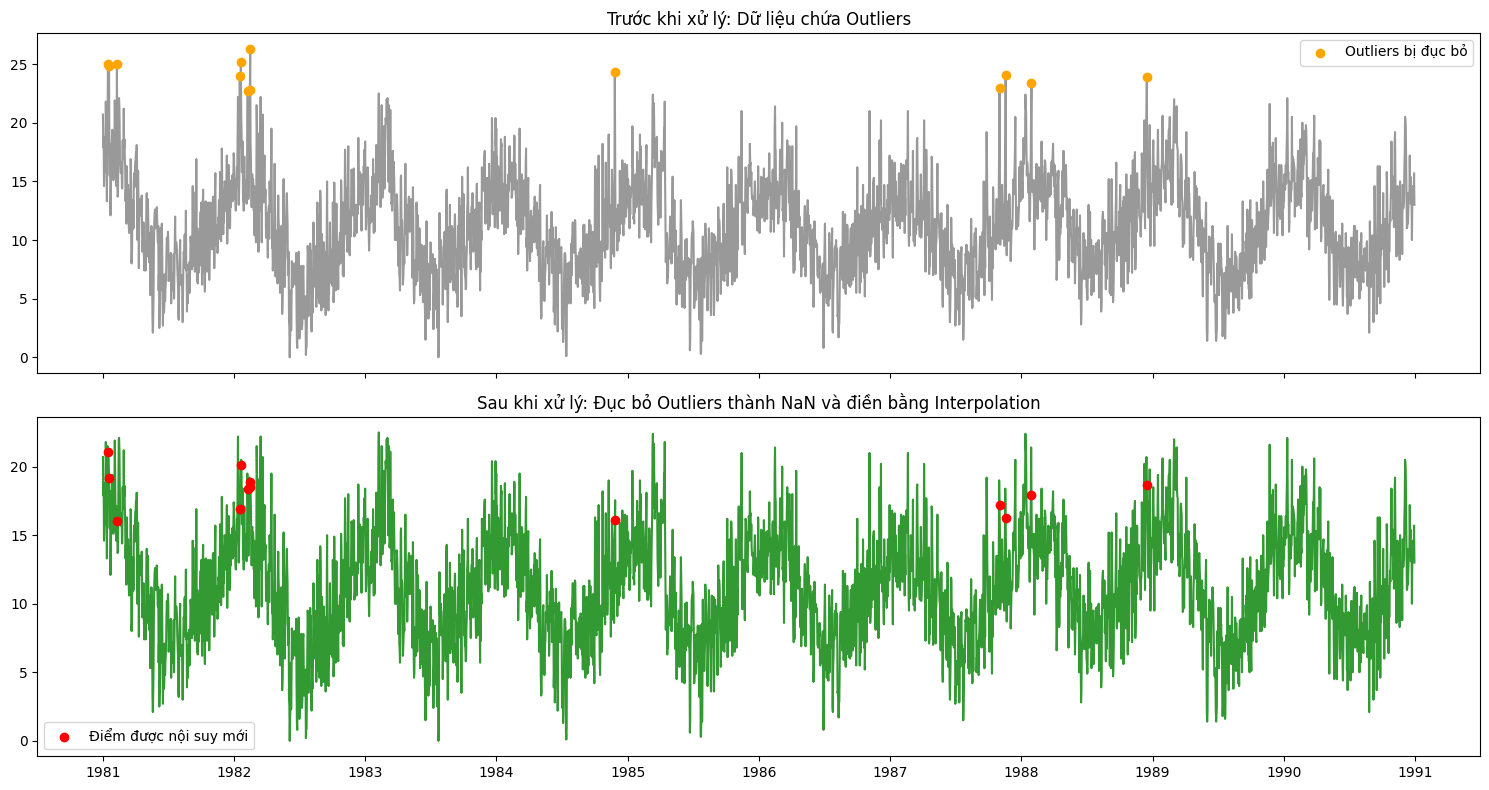

In [21]:
# Cách 2: Biến Outlier thành Missing (Ko khuyên dùng tránh trường hợp dữ liệu có giá trị)
df_handled_2 = df_outliers.copy()
mask_outliers = (df_handled_2['Temp'] < lower_bound) | (df_handled_2['Temp'] > upper_bound)
df_handled_2.loc[mask_outliers, 'Temp'] = np.nan
# Nội suy tuyến tính để lấp đầy các khoảng trống NaN vừa tạo
df_handled_2['Temp'] = df_handled_2['Temp'].interpolate(method='linear')
# Vẽ biểu đồ so sánh Trước và Sau
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
# 1. Trước khi xử lý
axes[0].plot(df_outliers.index, df_outliers['Temp'], color='gray', alpha=0.8)
axes[0].scatter(iqr_outliers.index, iqr_outliers['Temp'], color='orange', label='Outliers bị đục bỏ', zorder=5)
axes[0].set_title('Trước khi xử lý: Dữ liệu chứa Outliers')
axes[0].legend()
# 2. Sau khi xử lý bằng Interpolation
axes[1].plot(df_handled_2.index, df_handled_2['Temp'], color='green', alpha=0.8)
# Dùng mask để bôi đỏ những điểm vừa được nội suy tạo ra
axes[1].scatter(df_handled_2[mask_outliers].index, df_handled_2.loc[mask_outliers, 'Temp'], color='red', label='Điểm được nội suy mới', zorder=5)
axes[1].set_title('Sau khi xử lý: Đục bỏ Outliers thành NaN và điền bằng Interpolation')
axes[1].legend()
plt.tight_layout()
plt.show()

### Kết luận xử lý Missing Value và Outlier

#### 1. Về xử lý Missing Value (Dữ liệu khuyết thiếu):
- Dữ liệu bị khuyết thiếu **33 giá trị (chiếm ~0.9%)**.
- **So sánh 2 phương pháp:**
  - Forward-fill (FFill): Điền giá trị của ngày hôm trước vào ngày bị khuyết. Phương pháp này đơn giản nhưng tạo ra các đoạn đường thẳng nằm ngang (bước bậc thang), làm mất đi tính biến thiên tự nhiên giữa các ngày.
  - Linear Interpolation (Nội suy tuyến tính): Tạo đường nối mượt mà giữa điểm trước và điểm sau của khoảng khuyết thiếu.
- **Đánh giá & Khuyến nghị:** Trong dữ liệu chuỗi thời gian nhiệt độ liên tục, Linear Interpolation là phương pháp vượt trội và phù hợp nhất vì phản ánh đúng xu thế biến đổi dần của nhiệt độ giữa các ngày lân cận.


#### 2. Về xử lý Outlier (Giá trị dị biệt):
- **So sánh 2 phương pháp xử lý:**
  - Cách 1: Clipping / Winsorizing (Ép ngưỡng theo IQR): Ép các giá trị vượt ngưỡng về mức ranh giới 22.55°C. Giữ nguyên kích thước và cấu trúc liên tục của chuỗi thời gian, không tạo ra khoảng trống dữ liệu mới, nhưng làm bằng phẳng các đỉnh cực đại tự nhiên.
  - Cách 2: Đục bỏ thành NaN rồi Interpolate: Thay thế outlier thành NaN và nội suy lại. Phương pháp này làm mượt hoàn toàn các gai nhọn, tuy nhiên tiềm ẩn nguy cơ làm biến dạng bản chất tự nhiên của hiện tượng thời tiết cực đoan (như các đợt nắng nóng).
- **Đánh giá & Khuyến nghị:**
  - Nếu mục tiêu là huấn luyện mô hình dự báo nhạy cảm với ngoại lai (như Linear Regression, ARIMA): Nên sử dụng Clipping (Winsorizing) để kiềm chế ảnh hưởng của giá trị quá cao mà vẫn bảo toàn cấu trúc dữ liệu.
  - Trong thực tế phân tích khí hậu: Cần kết hợp xem xét ngữ cảnh nghiệp vụ, vì các đỉnh nhiệt độ này là hiện tượng thời tiết có thật và có thể mang giá trị dự báo quan trọng.

## Bài tập 5: Trực quan hoá dữ liệu chuỗi thời gian

### Line chart toàn bộ chuỗi:

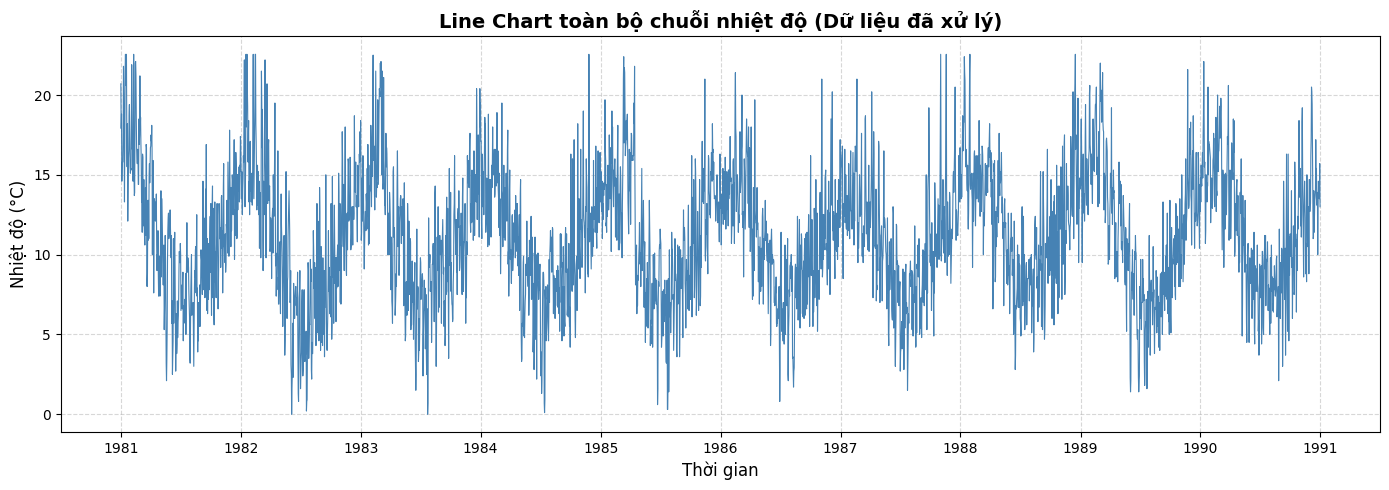

In [22]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_handled.index, df_handled['Temp'], color='steelblue', linewidth=0.8)
ax.set_title(
    'Line Chart toàn bộ chuỗi nhiệt độ (Dữ liệu đã xử lý)',
    fontsize=14,
    fontweight='bold',
)
ax.set_xlabel('Thời gian', fontsize=12)
ax.set_ylabel('Nhiệt độ (°C)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Rolling Mean và Rolling Std:

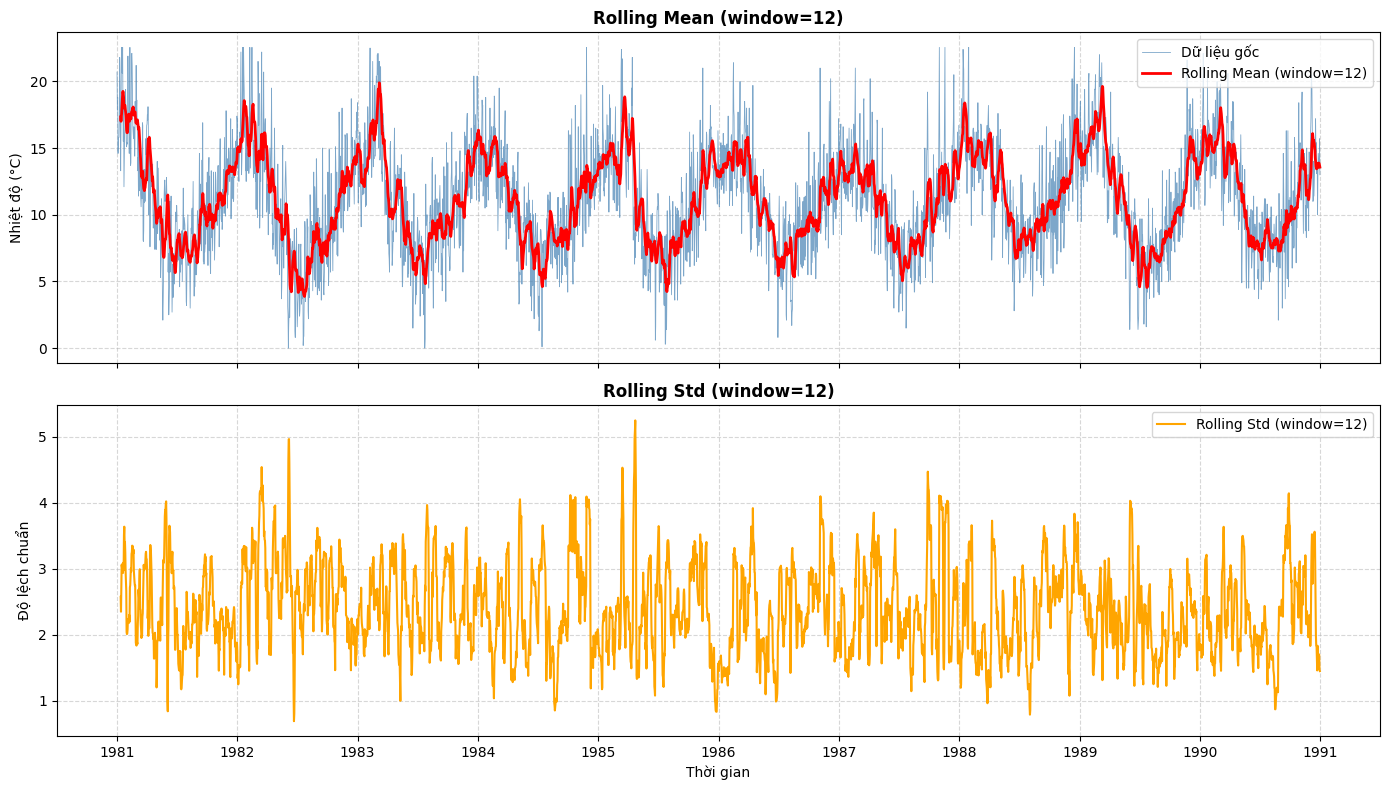

In [23]:
window = 12

rolling_mean = df_handled['Temp'].rolling(window=window).mean()
rolling_std = df_handled['Temp'].rolling(window=window).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Rolling Mean
axes[0].plot(df_handled.index, df_handled['Temp'], color='steelblue', linewidth=0.6, alpha=0.7, label='Dữ liệu gốc')
axes[0].plot(df_handled.index, rolling_mean, color='red', linewidth=2, label=f'Rolling Mean (window={window})')
axes[0].set_title('Rolling Mean (window=12)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nhiệt độ (°C)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Rolling Std
axes[1].plot(df_handled.index, rolling_std, color='orange', linewidth=1.5, label=f'Rolling Std (window={window})')
axes[1].set_title('Rolling Std (window=12)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Độ lệch chuẩn')
axes[1].set_xlabel('Thời gian')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Seasonal Plot theo tháng:

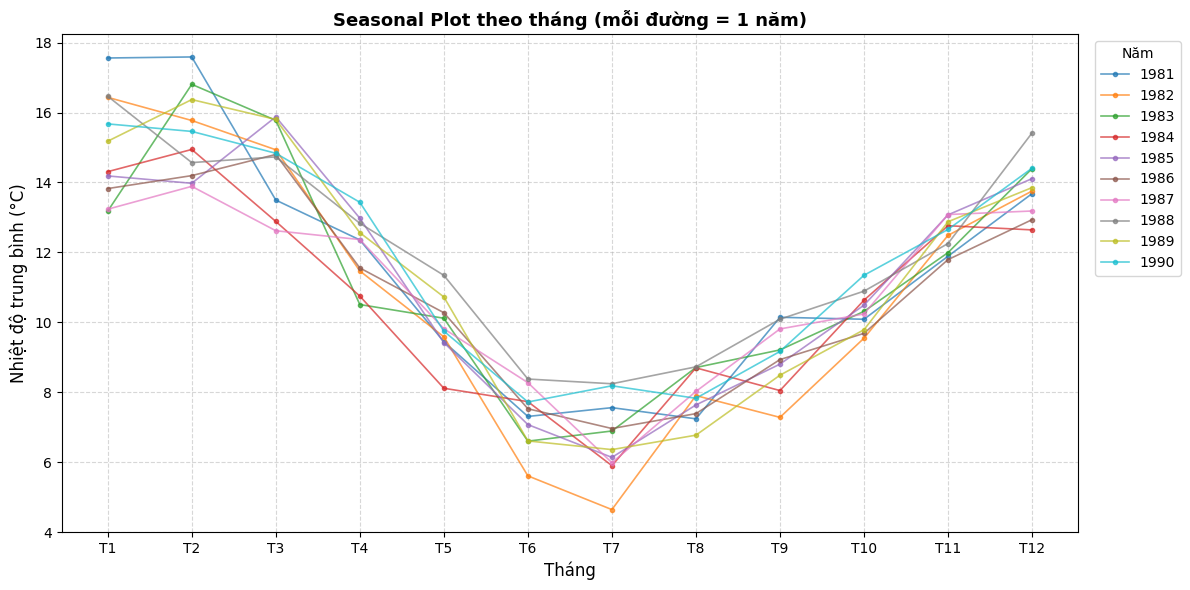

In [24]:
df_season = df_handled.copy()
df_season['Month'] = df_season.index.month
df_season['Year'] = df_season.index.year

# Nhóm theo tháng, tính trung bình mỗi tháng của từng năm
monthly_avg = df_season.groupby(['Year', 'Month'])['Temp'].mean().unstack(level=0)

fig, ax = plt.subplots(figsize=(12, 6))

for year in monthly_avg.columns:
    ax.plot(monthly_avg.index, monthly_avg[year], marker='o', markersize=3,
            linewidth=1.2, alpha=0.7, label=str(year))

ax.set_title('Seasonal Plot theo tháng (mỗi đường = 1 năm)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tháng', fontsize=12)
ax.set_ylabel('Nhiệt độ trung bình (°C)', fontsize=12)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12'])
ax.legend(title='Năm', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Heatmap Seasonality (month × year)

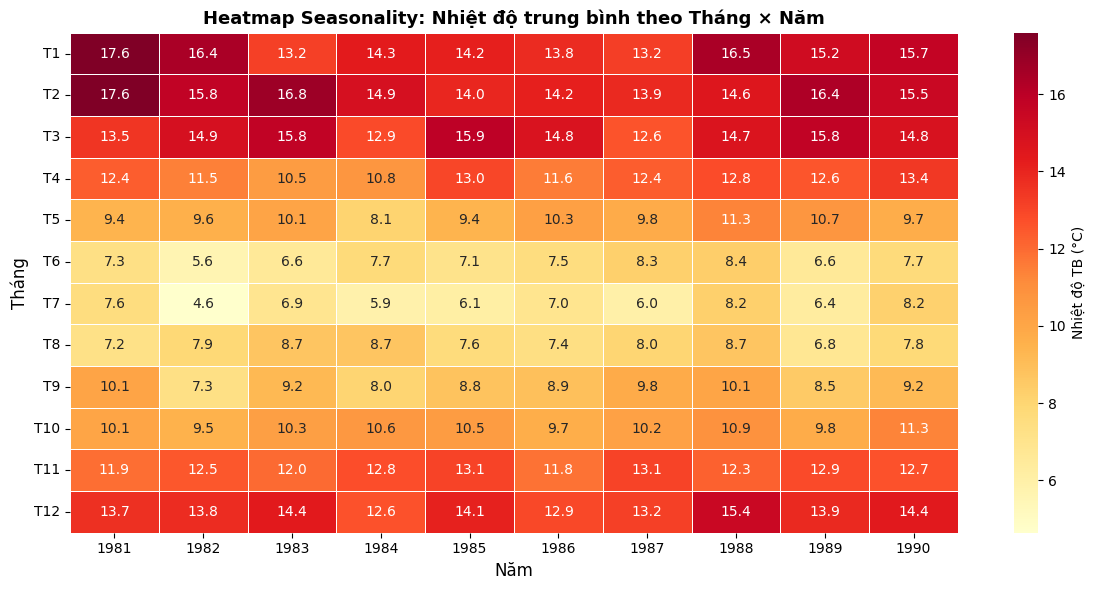

In [25]:
import seaborn as sns

pivot = df_season.groupby(['Month', 'Year'])['Temp'].mean().unstack(level=1)

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    ax=ax,
    linewidths=0.5,
    cbar_kws={'label': 'Nhiệt độ TB (°C)'},
)

ax.set_title(
    'Heatmap Seasonality: Nhiệt độ trung bình theo Tháng × Năm',
    fontsize=13,
    fontweight='bold',
)
ax.set_xlabel('Năm', fontsize=12)
ax.set_ylabel('Tháng', fontsize=12)
ax.set_yticklabels(
    ['T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12'],
    rotation=0,
)

plt.tight_layout()
plt.show()


### Kết luận tổng hợp phân tích chuỗi thời gian nhiệt độ

* **Xu hướng chung:** 
  * Chuỗi dữ liệu nhiệt độ toàn cục giai đoạn 1981–1991 cho thấy tính ổn định tương đối về mặt xu hướng dài hạn. 
  * Biểu đồ `Rolling Mean` và `Rolling Std` dao động ổn định quanh các biên độ nhất định, phản ánh chuỗi dữ liệu mang tính dừng hoặc dao động tuần hoàn ổn định.

* **Các mùa vụ nổi bật:** 
  * Chuỗi dữ liệu thể hiện rõ tính mùa vụ (Seasonality) cực kỳ mạnh mẽ theo chu kỳ 12 tháng.
  * Nhiệt độ đạt đỉnh cao nhất vào các tháng đầu năm (tháng 1, tháng 2) và cuối năm (tháng 12).
  * Ngược lại, nhiệt độ giảm sâu và chạm đáy vào giữa năm, đặc biệt tập trung vào các tháng mùa hè như tháng 6 và tháng 7.

* **Bất thường (nếu có):** 
  * Tại biểu đồ `Seasonal Plot` và `Heatmap`, có thể nhận thấy một số điểm ngoại lệ nhẹ như năm 1982 có mức nhiệt độ đáy tại tháng 7 giảm thấp bất thường (xuống gần 4.6°C), thấp hơn đáng kể so với mặt bằng chung các năm khác.
  * Độ lệch chuẩn (`Rolling Std`) xuất hiện một số đỉnh biến động mạnh tại các thời điểm chuyển giao mùa, cho thấy biên độ dao động nhiệt độ giữa các tháng trong một số năm có sự chênh lệch ngắn hạn.